# 4-04 섹터 로테이션 — 업종별 수익률로 자금 흐름 읽기

**질문 예시:** "오늘 어느 업종이 강했어?", "이번 주·이번 달 가장 강한 섹터랑 약한 섹터 정리해줘"

CHECK 원본(`4_시황재현/04_섹터로테이션`)은 **KRX 섹터지수**(반도체·증권·은행 등 15개 안팎)를 등락률로 줄 세웠습니다.
DeepSearch에는 섹터지수가 없습니다(지수는 코스피·코스닥 계열 11종뿐). 그래서 **업종지수를 직접 만듭니다.**

1. 전 종목 하루치 시세를 기준일·1주 전·1개월 전 세 번 받습니다(`GetStockPrices`, 호출 3회).
2. 종목 업종코드(KSIC 중분류)를 큰 업종 20여 개로 묶습니다. 지주회사는 따로, 금융지주는 증권·금융으로 둡니다.
3. 업종 수익률 = 기간 시작 시점 **시가총액 가중** 평균 수익률 (KRX 섹터지수와 같은 시총가중 방식이지만 구성 종목은 다릅니다).

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/4_market_brief/04_sector_rotation.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        if len(docs) < count:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"           # 기준일
MARKETS = ["KOSPI", "KOSDAQ"]  # 코스피만 보려면 ["KOSPI"]
MIN_N = 3                      # 종목이 이보다 적은 업종은 표에서 뺌

In [4]:
# 업종 분류: GetStockSymbols 의 industry_id = "KRI:10" + KSIC(10차) 코드. 예) KRI:10C2612000 → C26(중분류)
KSIC_DIV = {
    "A01": "농업", "A03": "어업", "C10": "식료품", "C11": "음료", "C12": "담배", "C13": "섬유제품",
    "C14": "의복·모피", "C15": "가죽·가방·신발", "C16": "목재", "C17": "펄프·종이", "C18": "인쇄",
    "C19": "석유정제품", "C20": "화학제품", "C21": "의약품", "C22": "고무·플라스틱", "C23": "비금속광물",
    "C24": "1차금속", "C25": "금속가공", "C26": "전자부품·컴퓨터·통신장비", "C27": "의료·정밀·광학기기",
    "C28": "전기장비", "C29": "기타 기계·장비", "C30": "자동차·부품", "C31": "기타 운송장비(조선 등)",
    "C32": "가구", "C33": "기타 제품", "D35": "전기·가스", "E38": "폐기물·재생", "F41": "종합건설",
    "F42": "전문공사", "G45": "자동차 판매", "G46": "도매", "G47": "소매", "H49": "육상운송",
    "H50": "수상운송", "H51": "항공운송", "H52": "창고·운송서비스", "I55": "숙박", "J58": "출판·소프트웨어",
    "J59": "영상·오디오 제작", "J60": "방송", "J61": "통신", "J62": "IT서비스·SI", "J63": "정보서비스(포털 등)",
    "K64": "금융업", "K65": "보험", "K66": "금융서비스(증권 등)", "L68": "부동산", "M70": "연구개발(바이오 등)",
    "M71": "전문서비스", "M72": "엔지니어링", "M73": "기타 과학기술서비스", "N74": "시설관리",
    "N75": "사업지원서비스", "N76": "임대", "P85": "교육", "R90": "창작·예술", "R91": "스포츠·오락",
    "S95": "수리", "S96": "기타 개인서비스",
}
# 큰 업종 묶음 (KRX 섹터지수와 1:1은 아님 — 비교하기 쉬운 수준으로 직접 묶은 근사)
_GROUPS = {
    "반도체·전자": ["C26"], "2차전지·전기장비": ["C28"], "자동차": ["C30", "G45"], "조선·운송장비": ["C31"],
    "기계": ["C29"], "화학·정유": ["C19", "C20"], "제약·바이오": ["C21", "M70"], "의료·정밀기기": ["C27"],
    "철강·금속": ["C24", "C25"], "소재(비금속·종이·플라스틱)": ["C16", "C17", "C22", "C23"],
    "음식료·생활소비재": ["A01", "A03", "C10", "C11", "C12", "C13", "C14", "C15", "C18", "C32", "C33"],
    "건설": ["F41", "F42", "M72"], "유통·상사": ["G46", "G47"], "운송·물류": ["H49", "H50", "H51", "H52"],
    "소프트웨어·인터넷": ["J58", "J62", "J63"], "미디어·통신·엔터": ["J59", "J60", "J61", "R90", "R91"],
    "증권·금융": ["K64", "K66"], "보험": ["K65"], "유틸리티·환경": ["D35", "E38"],
    "기타 서비스": ["I55", "L68", "M71", "M73", "N74", "N75", "N76", "P85", "S95", "S96"],
}
DIV2GROUP = {d: g for g, ds_ in _GROUPS.items() for d in ds_}
FIN_HOLDING = ("금융", "신한지주")  # 이름에 들어 있으면 금융지주로 봄 (KB금융, 신한지주, 하나금융지주, 메리츠금융지주 …)


def add_sector(df):
    """industry_id·industry_name → 중분류(div, div_name)와 큰 묶음(sector). 지주회사는 따로 떼고, 금융지주는 증권·금융으로."""
    df = df.copy()
    df["div"] = df["industry_id"].str[6:9]
    df["div_name"] = df["div"].map(KSIC_DIV).fillna(df["div"])
    df["sector"] = df["div"].map(DIV2GROUP).fillna("기타 서비스")
    hold = df["industry_name"].eq("지주회사")
    fin = df["name"].str.contains("|".join(FIN_HOLDING))
    df.loc[hold & ~fin, ["sector", "div_name"]] = ["지주회사", "지주회사"]
    df.loc[hold & fin, ["sector", "div_name"]] = ["증권·금융", "금융지주"]
    return df

## 1. 비교 날짜 정하기
지수 일별 데이터로 거래일 달력을 만들어 1주(5거래일) 전, 1개월(약 21거래일) 전 날짜를 고릅니다.

In [5]:
d = pd.Timestamp(ASOF)
ix = index_prices((d - pd.Timedelta(days=50)).date(), d.date())
days = sorted(ix["date"].unique())
DAY, W1, M1, D1 = days[-1], days[-6], days[-22], days[-2]
print("기준일", DAY.date(), "| 1주 전", W1.date(), "| 1개월 전", M1.date())
kospi = ix[ix["symbol"] == "KRX:KOSPI"].set_index("date")["close"]
kosdaq = ix[ix["symbol"] == "KRX:KOSDAQ"].set_index("date")["close"]
bench = pd.DataFrame({"1일(%)": [kospi[DAY] / kospi[D1] - 1, kosdaq[DAY] / kosdaq[D1] - 1],
                      "1주(%)": [kospi[DAY] / kospi[W1] - 1, kosdaq[DAY] / kosdaq[W1] - 1],
                      "1개월(%)": [kospi[DAY] / kospi[M1] - 1, kosdaq[DAY] / kosdaq[M1] - 1]},
                     index=["코스피", "코스닥"]).mul(100).round(2)
bench

기준일 2026-11-24 | 1주 전 2026-11-17 | 1개월 전 2026-10-26


,1일(%),1주(%),1개월(%)
코스피,6.32,0.76,-8.47
코스닥,4.79,2.43,-8.43


## 2. 전 종목 수익률과 업종 묶기

In [6]:
cols = ["close", "change_rate", "market_cap", "volume"]
now = all_stocks(DAY, columns=cols)
now = add_sector(now[now["market"].isin(MARKETS) & (now["date"] == DAY)])
base = {}
for label, day in (("1주", W1), ("1개월", M1)):
    b = all_stocks(day, columns=["close", "market_cap"])
    base[label] = b[b["date"] == day].set_index("symbol")[["close", "market_cap"]]

df = now.set_index("symbol")
df["w_1일"] = df["market_cap"] / (1 + df["change_rate"])   # 전일 시총 근사
df["r_1일"] = df["change_rate"]
for label in base:
    df[f"r_{label}"] = df["close"] / base[label]["close"] - 1
    df[f"w_{label}"] = base[label]["market_cap"]
print("종목 수:", len(df), "| 1개월 전 시세가 없는 종목(그 뒤 상장 등):", df["r_1개월"].isna().sum())
print(PRICE_NOTICE)

종목 수: 2663 | 1개월 전 시세가 없는 종목(그 뒤 상장 등): 17
※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). 거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).


## 3. 업종 수익률 표 (큰 묶음)

In [7]:
def sector_table(df, key):
    out = {}
    for name, g in df.groupby(key):
        row = {"종목 수": len(g), "시가총액": g["market_cap"].sum()}
        for p in ("1일", "1주", "1개월"):
            x = g[[f"r_{p}", f"w_{p}"]].dropna()
            row[f"{p}(%)"] = (x[f"r_{p}"] * x[f"w_{p}"]).sum() / x[f"w_{p}"].sum() * 100 if len(x) else None
        row["대표 종목"] = ", ".join(g.nlargest(3, "market_cap")["name"])
        out[name] = row
    t = pd.DataFrame(out).T
    t = t[t["종목 수"] >= MIN_N]
    for c in ("1일(%)", "1주(%)", "1개월(%)"):
        t[c] = t[c].astype(float).round(2)
    t["시가총액"] = t["시가총액"].map(krw)
    return t

sec = sector_table(df, "sector").sort_values("1개월(%)", ascending=False)
sec["1개월 순위"] = range(1, len(sec) + 1)
sec["1주 순위"] = sec["1주(%)"].rank(ascending=False).astype(int)
sec["순위 변화(1주−1개월)"] = sec["1개월 순위"] - sec["1주 순위"]   # +면 최근 1주에 순위가 올라옴
sec

,종목 수,시가총액,1일(%),1주(%),1개월(%),대표 종목,1개월 순위,1주 순위,순위 변화(1주−1개월)
운송·물류,28,58.5조,5.03,1.21,8.20,"HMM, 현대글로비스, 대한항공",1,6,-5
증권·금융,141,277.8조,4.19,-1.38,1.03,"KB금융, 신한지주, 하나금융지주",2,12,-10
미디어·통신·엔터,71,56.0조,2.16,-5.36,0.91,"SK텔레콤, KT, 하이브",3,20,-17
음식료·생활소비재,164,59.5조,2.06,-1.02,-0.74,"KT&G, 삼양식품, 오리온",4,11,-7
기타 서비스,100,32.9조,1.70,-1.66,-1.87,"코웨이, 에스원, 롯데렌탈",5,14,-9
소재(비금속·종이·플라스틱),117,25.6조,4.05,-2.00,-2.15,"한국타이어앤테크놀로지, 티씨케이, 금호타이어",6,15,-9
지주회사,83,253.4조,5.44,1.45,-2.26,"SK스퀘어, SK, HD한국조선해양",7,5,2
자동차,112,143.2조,11.34,4.65,-2.90,"현대차, 기아, 현대모비스",8,1,7
소프트웨어·인터넷,273,120.6조,5.32,-3.66,-4.57,"NAVER, 삼성에스디에스, 카카오",9,18,-9
제약·바이오,253,220.5조,1.55,-3.80,-5.12,"삼성바이오로직스, 셀트리온, 알테오젠",10,19,-9


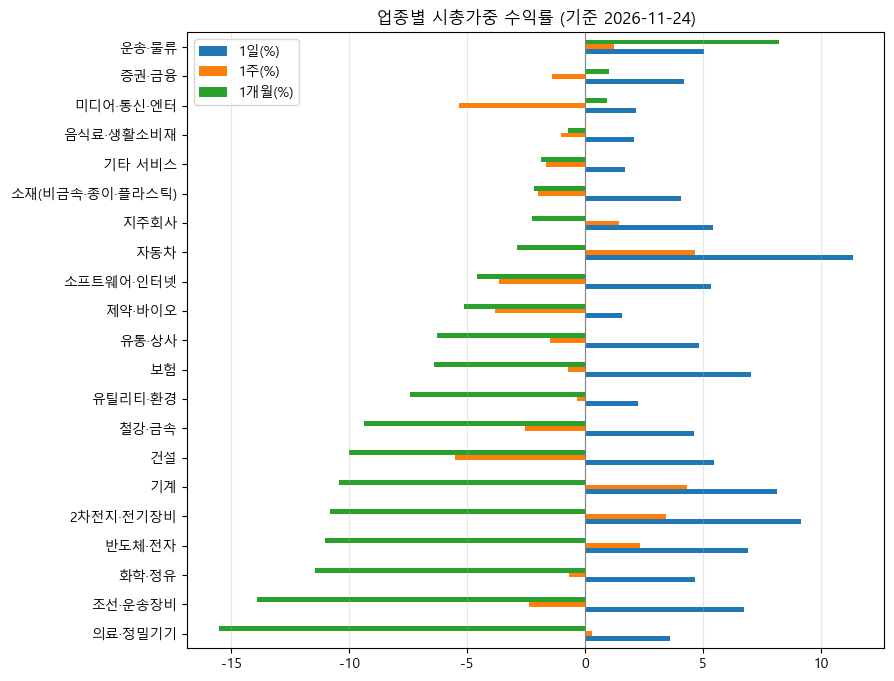

In [8]:
ax = sec[["1일(%)", "1주(%)", "1개월(%)"]].iloc[::-1].plot.barh(figsize=(9, 8), title=f"업종별 시총가중 수익률 (기준 {DAY.date()})")
ax.axvline(0, color="gray", lw=.8); ax.grid(axis="x", alpha=.3)

## 4. 무엇이 업종을 움직였나 — 1개월 최강·최약 업종의 기여 종목
기여도 = 종목 비중(1개월 전 시총 기준) × 종목 수익률. 대형주 한두 개가 업종 수익률을 좌우하는지 확인합니다.

In [9]:
def contributors(sector, n=5):
    g = df[(df["sector"] == sector)].dropna(subset=["r_1개월"])
    w = g["w_1개월"] / g["w_1개월"].sum()
    c = (w * g["r_1개월"] * 100).rename("기여(%p)")
    out = pd.DataFrame({"종목": g["name"], "비중(%)": (w * 100).round(1), "1개월(%)": (g["r_1개월"] * 100).round(1),
                        "기여(%p)": c.round(2)})
    return out.reindex(c.abs().sort_values(ascending=False).index).head(n).reset_index(drop=True)

for s in (sec.index[0], sec.index[-1]):
    print(f"[{s}] 1개월 {sec.loc[s, '1개월(%)']:+.2f}%")
    display(contributors(s))

[운송·물류] 1개월 +8.20%


,종목,비중(%),1개월(%),기여(%p)
0,현대글로비스,24.4,17.2,4.20
1,대한항공,17.1,24.1,4.12
2,팬오션,5.9,-20.0,-1.19
3,아시아나항공,2.6,24.1,0.62
4,제주항공,0.8,52.4,0.41


[의료·정밀기기] 1개월 -15.53%


,종목,비중(%),1개월(%),기여(%p)
0,티에스이,12.4,-31.1,-3.86
1,씨어스,5.0,-48.4,-2.41
2,클래시스,8.3,-20.6,-1.70
3,큐리옥스바이오시스템즈,4.7,-29.8,-1.40
4,디아이,4.8,-28.9,-1.38


## 5. 세부 업종(KSIC 중분류) 상위·하위
큰 묶음 안에서 어느 세부 업종이 강했는지 봅니다(종목 5개 이상만).

In [10]:
div = sector_table(df, "div_name")
div = div[div["종목 수"] >= 5].sort_values("1주(%)", ascending=False)
print("[최근 1주 강한 세부 업종 7]"); display(div.head(7))
print("[최근 1주 약한 세부 업종 7]"); display(div.tail(7))

[최근 1주 강한 세부 업종 7]


,종목 수,시가총액,1일(%),1주(%),1개월(%),대표 종목
영상·오디오 제작,35,15.3조,1.19,12.98,7.47,"하이브, 에스엠, JYP Ent."
방송,10,2.1조,-0.97,12.47,10.36,"CJ ENM, SBS, 스카이라이프"
출판·소프트웨어,201,52.9조,6.71,4.71,-1.01,"현대오토에버, 크래프톤, NC"
자동차·부품,106,142.6조,11.39,4.69,-2.87,"현대차, 기아, 현대모비스"
기타 기계·장비,225,146.1조,8.12,4.34,-10.41,"두산에너빌리티, 한미반도체, 레인보우로보틱스"
전기장비,92,229.2조,9.16,3.44,-10.82,"LG에너지솔루션, 삼성SDI, LS ELECTRIC"
창고·운송서비스,6,16.2조,8.28,2.55,16.88,"현대글로비스, 한국공항, 선광"


[최근 1주 약한 세부 업종 7]


,종목 수,시가총액,1일(%),1주(%),1개월(%),대표 종목
펄프·종이,22,2.1조,1.61,-5.50,-4.59,"에스엠국일, 신대양제지, 아세아제지"
정보서비스(포털 등),39,44.0조,4.11,-5.59,-4.77,"NAVER, 카카오, 다우기술"
가죽·가방·신발,7,1.1조,-0.83,-6.30,-7.82,"조광피혁, 제이에스코퍼레이션, SYTS"
종합건설,37,23.0조,4.65,-6.98,-18.00,"현대건설, 대우건설, GS건설"
석유정제품,5,27.0조,1.32,-9.75,-29.94,"SK이노베이션, S-Oil, 한국쉘석유"
통신,14,33.7조,2.95,-13.33,-2.55,"SK텔레콤, KT, LG유플러스"
IT서비스·SI,33,23.7조,4.50,-15.49,-11.35,"삼성에스디에스, LG씨엔에스, DB"


## 6. 읽는 법과 한계
- **위험선호 vs 방어:** 반도체·2차전지·기계·증권이 앞서면 위험선호(risk-on), 음식료·통신·유틸리티가 앞서면 방어(risk-off)로 읽습니다.
- **순위 변화가 큰 업종**은 자금이 새로 들어오거나 빠지는 곳입니다(최근 1주 순위가 1개월 순위보다 높으면 +).
- **KRX 섹터지수와 숫자가 다릅니다.** 업종 분류(KSIC 기준, 예: 삼성물산은 '도매'), 구성 종목(전 종목), 가중 방식(유동주식 아닌 전체 시총)이 다릅니다.
- 업종 분류는 현재 기준 하나뿐이고, 현재 상장 종목만 들어갑니다(기간 중 상장폐지 종목 제외).
- 투자자별 수급과 결합("외국인이 들어온 업종")은 DeepSearch에 수급 데이터가 없어 할 수 없습니다.